## PREPROCESSING

In [8]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np

from spellitout.spellitout import SpellItOut
from spellitout.plotting import plot_erd_grid
from spellitout.utils import make_annotations_from_events

from tqdm import tqdm
# subjects = ['c9','d7','f9','h9','i1','i7','i8','j3','j4','j5','j6','j7','j8','k1','k2','k3','k4','k5','k6','k7']
mode = 'silent'
subjects = [1]
runs = [1,2,3]
fmin,fmax = 1,100

dataset = SpellItOut(mode, subjects=subjects, runs=runs)

data = dataset.get_data(preload=False)
    
for subject_id,subject_runs in tqdm(data.items()):
    for run_id, run in tqdm(subject_runs.items(),leave=False):
        raw,_ = run
        raw.load_data()
        # raw.resample(256,verbose=False)
        raw.drop_channels(['AF7', 'AF8'])
        raw.notch_filter([50,100],verbose='error')
        raw.filter(fmin, fmax,verbose='error')

raw = mne.concatenate_raws([data[f'sub-{subject:02d}'][f'run-{run}'][0] for run in runs for subject in subjects])

  0%|          | 0/1 [00:00<?, ?it/s]

Reading 0 ... 1431358  =      0.000 ...   698.905 secs...


Reading 0 ... 1431470  =      0.000 ...   698.960 secs...


Reading 0 ... 1430207  =      0.000 ...   698.343 secs...


100%|██████████| 1/1 [00:22<00:00, 22.89s/it]


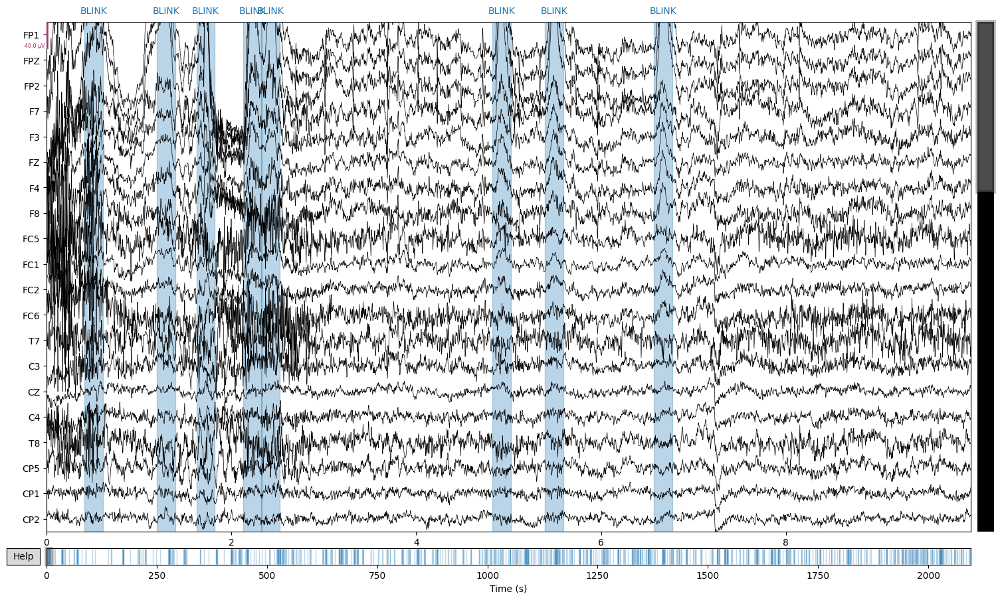

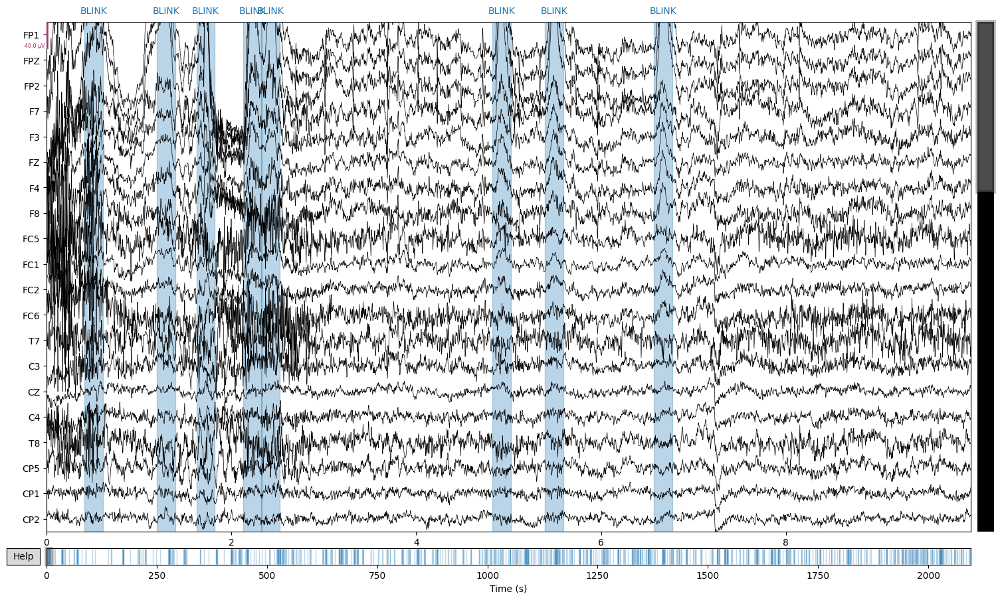

In [ ]:
# annotate blinks
eog_events = mne.preprocessing.find_eog_events(raw, ch_name=['FP1', 'FP2', 'FPZ'], verbose=False)
# annotate the EOG events in the raw data
eog_annotations = mne.Annotations(onset=(eog_events[:, 0] / raw.info['sfreq'])-0.1,
                                  duration=0.2,
                                  description='BLINK')
raw.set_annotations(eog_annotations)

# Annotate high amplitude events
mne.preprocessing.annotate_muscle_zscore(raw, ch_type='eeg', threshold=4.0, min_length_good=0.2, filter_freq=[110, 140], verbose=False)

raw.plot()

In [14]:
subj = "sub-02"
task = "silent"
from pathlib import Path
import mne


data_path = Path(f"derivatives/preprocessing/")

for run in [1, 2, 3]:
    run_path = data_path / subj / "ses-01" / "eeg" / f"{subj}_ses-01_task-{task}_run-0{run}_desc-minproc_raw.fif"
    raw = mne.io.read_raw_fif(run_path, preload=True, verbose=False)
    break

# raw.set_annotations(raw.annotations[np.isin(raw.annotations.description, ["BLINK", "MUSCLE_CANDIDATE", "AMPLITUDE_CANDIDATE"])])

np.unique(raw.annotations.description, return_counts=True)
# raw.plot()

(array(['fixation', 'repetition_cue', 'rhythm_dots', 'sentence_audio',
        'syllable_cue', 'syllable_listening', 'trial_end', 'trial_start',
        'word_listening'], dtype='<U18'),
 array([ 20,  20,  60,  20, 462, 462,  20,  20, 224]))

In [5]:
run_path

WindowsPath('derivatives/preprocessing/sub-01/ses-01/eeg/sub-01_ses-01_silent_run-01_desc-minproc_raw.fif')

## ICA

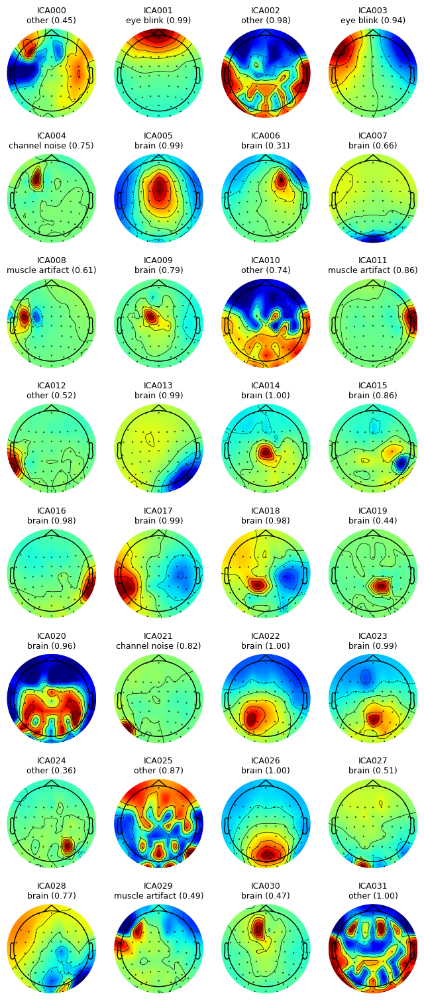

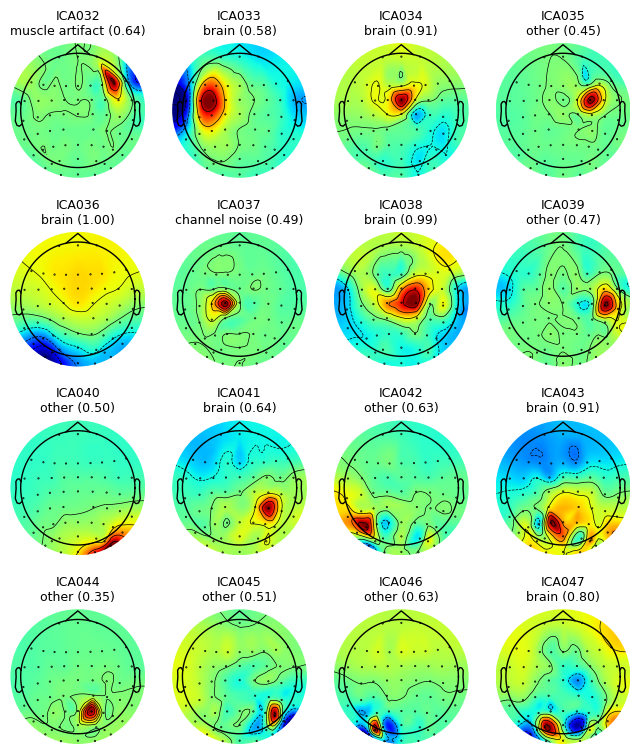

In [2]:

import mne    
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

base_path = Path(r"D:\SHARED\PhD\data\Spell-IT-OUT\derivatives\preprocessing\task-silent\sub-01\ses-01\eeg")

ica_path = base_path / "sub-01_ses-01_task-silent_desc-amica_ica.fif"
icalabels_path = base_path / "sub-01_ses-01_task-silent_desc-amica_iclabels.tsv"
icalabels = pd.read_csv(icalabels_path, sep='\t')


ica = mne.preprocessing.read_ica(ica_path, verbose=False)
raws = []
for run in [1,2,3]:
    raw_path = base_path / f"sub-01_ses-01_task-silent_run-{run:02d}_desc-prep_raw.fif"
    raw = mne.io.read_raw_fif(raw_path, preload=True, verbose=False)
    raws.append(raw)
raw = mne.concatenate_raws(raws)
raw.pick('eeg')

# ica.plot_components()

def save_component_plots(
    ica: mne.preprocessing.ICA,
    labels: pd.DataFrame,
    output_dir: Path,
    base: str,
    n_rows: int = 8,
    n_columns: int = 4,
) -> None:
    """Save labelled ICA topographies in pages suitable for quick inspection."""
    components_per_figure = n_rows * n_columns
    n_components = len(labels)
    for page, start in enumerate(range(0, n_components, components_per_figure), start=1):
        component_indices = np.arange(start, min(start + components_per_figure, n_components))
        fig, axes = plt.subplots(n_rows, n_columns, figsize=(2*n_columns, 2.4*n_rows))
        axes = axes.ravel()
        ica.plot_components(
            picks=component_indices,
            axes=axes[:len(component_indices)],
            cmap="jet",
            nrows=n_rows,
            ncols=n_columns,
            show=False,
        )
        for axis, (_, component) in zip(axes, labels.iloc[component_indices].iterrows()):
            predicted_label = component["predicted_label"]
            probability = component[predicted_label]
            axis.set_title(
                f"{axis.get_title()}\n{predicted_label} ({probability:.2f})",
                fontsize=9,
            )
        for axis in axes[len(component_indices):]:
            axis.set_visible(False)
        # fig.savefig(
        #     output_dir / f"{base}_desc-amica_components-{page:02d}.png",
        #     dpi=150,
        #     bbox_inches="tight",
        # )
        plt.show()
        plt.close(fig)


save_component_plots(
    ica=ica,
    labels=icalabels,
    output_dir=base_path,
    base="sub-01_ses-01_task-silent",
    n_rows=8,
    n_columns=4
)

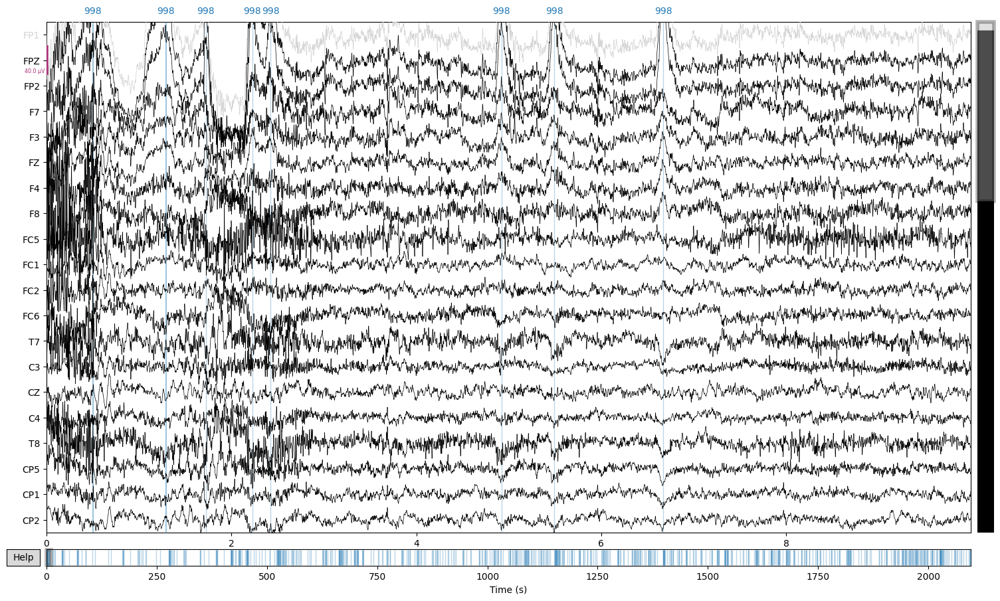

In [ ]:
raws = []
for run in [1,2,3]:
    raw_path = base_path / f"sub-01_ses-01_task-silent_run-{run:02d}_desc-prep_raw.fif"
    raw = mne.io.read_raw_fif(raw_path, preload=True, verbose=False)
    raws.append(raw)
raw = mne.concatenate_raws(raws)
raw.pick('eeg')
raw.set_annotations(None)
raw.plot()

eog_events = mne.preprocessing.find_eog_events(raw, ch_name=['FP1', 'FP2', 'FPZ'], verbose=False)
# annoate the EOG events in the raw data
eog_event_id = 998  # Arbitrary event ID for EOG events
eog_annotations = mne.Annotations(onset=eog_events[:, 0] / raw.info['sfreq'],
                                  duration=0.0,
                                  description=eog_event_id)
raw.set_annotations(eog_annotations)
raw.plot()


# Data Exploration

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np

from spellitout.spellitout import SpellItOut
from spellitout.plotting import plot_erd_grid
from spellitout.utils import make_annotations_from_events

from tqdm import tqdm
# subjects = ['c9','d7','f9','h9','i1','i7','i8','j3','j4','j5','j6','j7','j8','k1','k2','k3','k4','k5','k6','k7']
mode = 'silent'
subjects = [1]
runs = [1,2,3]
fmin,fmax = 1,100

dataset = SpellItOut(mode, subjects=subjects, runs=runs)

data = dataset.get_data(preload=False)
    
for subject_id,subject_runs in tqdm(data.items()):
    for run_id, run in tqdm(subject_runs.items(),leave=False):
        raw,_ = run
        raw.load_data()
        # raw.resample(256,verbose=False)
        raw.drop_channels(['AF7', 'AF8'])
        raw.notch_filter(50,verbose='error')
        raw.filter(fmin, fmax,verbose='error')

raw = mne.concatenate_raws([data[f'sub-{subject:02d}'][f'run-{run}'][0] for run in runs for subject in subjects])

  0%|          | 0/1 [00:00<?, ?it/s]

Reading 0 ... 1431358  =      0.000 ...   698.905 secs...


Reading 0 ... 1431470  =      0.000 ...   698.960 secs...


Reading 0 ... 1430207  =      0.000 ...   698.343 secs...


100%|██████████| 1/1 [00:24<00:00, 24.39s/it]


## ERP (dots & syllables)

Using matplotlib as 2D backend.


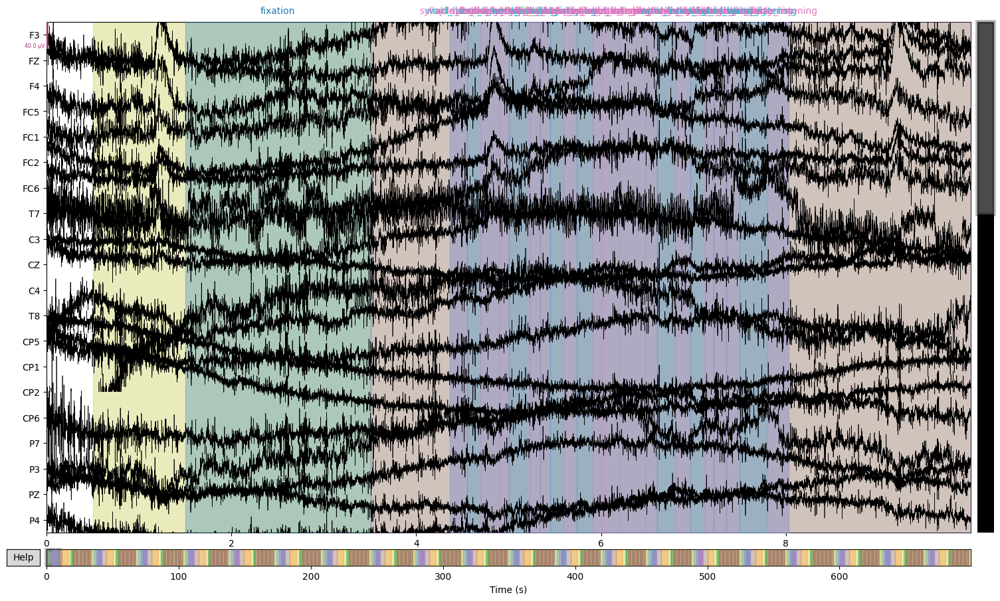

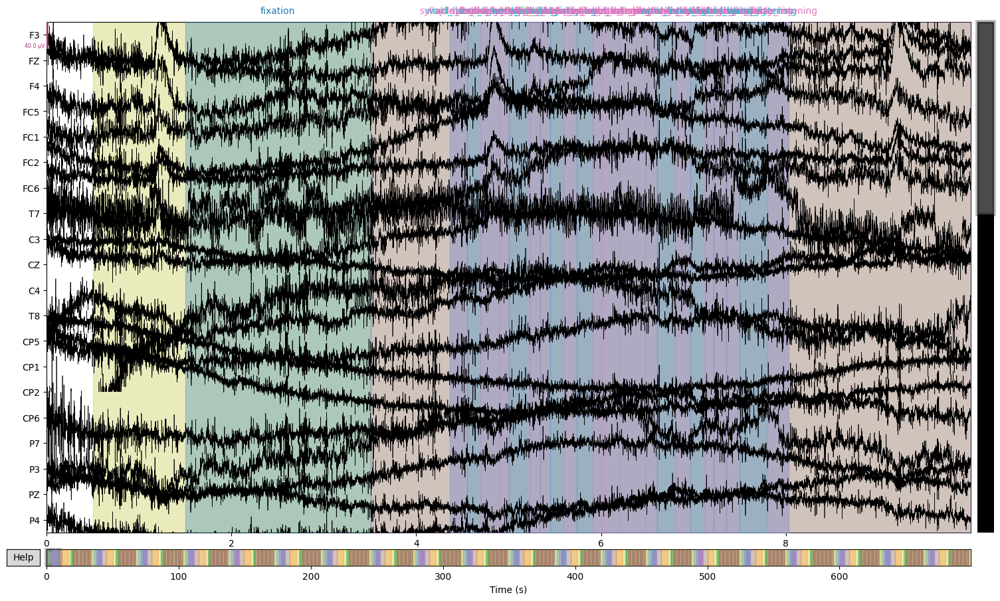

In [4]:
raw.plot()

No projector specified for this dataset. Please consider the method self.add_proj.


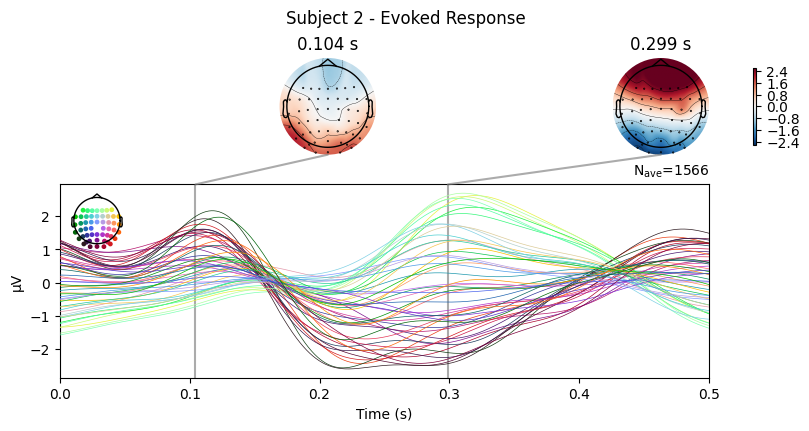

In [ ]:
events,ev_map = mne.events_from_annotations(raw, verbose='error')
ev_map = {k: v for k, v in ev_map.items() if k in ['syllable_cue','rhythm_dots']}
epochs = mne.Epochs(raw, events, event_id=ev_map, tmin=0, tmax=0.5, baseline=None, preload=True, verbose='error')
evoked = epochs.average()
evoked.plot_joint(title=f"Subject {subject} - Evoked Response", ts_args={'time_unit': 's'})

## ERD/ERS

In [5]:
ignore_checkpoints = True
tfr_syll_file = ckpt_path / f'{mode}-grand_average-csd-syll-epoch=(-1.6, 2.2)-tfr.h5'
epochs_syll_file = ckpt_path / f'{mode}-grand_average-csd-syll-epoch=(-1.6, 2.2)-epo.fif'

tfr_dots_file = ckpt_path / f'{mode}-grand_average-csd-dots-epoch=(-1.6, 2.2)-tfr.h5'
epochs_dots_file = ckpt_path / f'{mode}-grand_average-csd-dots-epoch=(-1.6, 2.2)-epo.fif'

tfr_full_trial_file = ckpt_path / f'{mode}-grand_average-csd-full_trial-epoch=(-10, 25)-tfr.h5'
epochs_full_trial_file = ckpt_path / f'{mode}-grand_average-csd-full_trial-epoch=(-10, 25)-epo.fif'

tfr_fix_file = ckpt_path / f'{mode}-grand_average-csd-fixation-epoch=(-1.5, -0.1)-tfr.h5'
epochs_fix_file = ckpt_path / f'{mode}-grand_average-csd-fixation-epoch=(-1.5, -0.1)-epo.fif'

ckpt_path.mkdir(parents=True, exist_ok=True)
# TFR delle sillabe
if ignore_checkpoints or not os.path.exists(tfr_syll_file): 
    print("Calcolando TFR per le sillabe...")
    target_epoch = (-0.1,0.7) 
    epochs = mne.Epochs(raw, events, ev_map['syllable_cue'], -1.6, 2.2, 
                        proj=True, picks='eeg', baseline=None, 
                        reject=reject, preload=True, 
                        # verbose='error'
                        )
    epochs = mne.preprocessing.compute_current_source_density(epochs)
    tfr = epochs.compute_tfr(method="morlet",freqs=freqs, n_cycles=n_cycles, use_fft=True,
                    return_itc=False, average=True, n_jobs=-1, verbose='error')
    # tfr.crop(target_epoch[0], target_epoch[1])
    tfr.save(tfr_syll_file, overwrite=True)
    epochs.save(epochs_syll_file, overwrite=True)

# TFR dei puntini
if ignore_checkpoints or not os.path.exists(tfr_dots_file): 
    print("Calcolando TFR per i puntini pre-sillaba...")
    epochs = mne.Epochs(raw, events, ev_map['rhythm_dots'], -1.6, 2.2, 
                        proj=True, picks='eeg', baseline=None, 
                        reject=reject, preload=True, 
                        # verbose='error'
                        )
    epochs = mne.preprocessing.compute_current_source_density(epochs)
    tfr = epochs.compute_tfr(method="morlet",freqs=freqs, n_cycles=n_cycles, use_fft=True,
                    return_itc=False, average=True, n_jobs=-1, verbose='error')
    # tfr.crop(target_epoch[0], target_epoch[1])
    tfr.save(tfr_dots_file, overwrite=True)
    epochs.save(epochs_dots_file, overwrite=True)

# TFR del full_trial

if ignore_checkpoints or not os.path.exists(tfr_full_trial_file):
    print("Calcolando TFR per il full trial...")
    b_epochs = mne.Epochs(raw, events, ev_map['repetition_cue'], -10, 25, 
                        proj=True, picks='eeg', baseline=None, 
                        reject=reject, preload=True, 
                        # verbose='error'
                        )
    
    b_epochs = mne.preprocessing.compute_current_source_density(b_epochs)
    tfr_baseline = b_epochs.compute_tfr(method="morlet",freqs=freqs, n_cycles=n_cycles, use_fft=True,
                    return_itc=False, average=True, n_jobs=-1, verbose='error')
    tfr_baseline.save(tfr_full_trial_file, overwrite=True)
    b_epochs.save(epochs_full_trial_file, overwrite=True)

# TFR della fixation
if ignore_checkpoints or not os.path.exists(tfr_fix_file):
    print("Calcolando TFR per la fixation...")
    b_epochs = mne.Epochs(raw, events, ev_map['fixation'], -3, 1.5, 
                        proj=True, picks='eeg', baseline=None, 
                        reject=reject, preload=True, 
                        # verbose='error'
                        )
    
    b_epochs = mne.preprocessing.compute_current_source_density(b_epochs)
    tfr_baseline = b_epochs.compute_tfr(method="morlet",freqs=freqs, n_cycles=n_cycles, use_fft=True,
                    return_itc=False, average=True, n_jobs=-1, verbose='error')
    tfr_baseline.save(tfr_fix_file, overwrite=True)
    b_epochs.save(epochs_fix_file, overwrite=True)

Calcolando TFR per le sillabe...
Not setting metadata
1386 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 1386 events and 974 original time points ...
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Rejecting  epoch based on EEG : ['T7']
    Re

Reading d:\SHARED\PhD\data\Spell-IT-OUT_V2\derivatives\checkpoints\silent-grand_average-csd-syll-epoch=(-1.6, 2.2)-tfr.h5 ...
Reading d:\SHARED\PhD\data\Spell-IT-OUT_V2\derivatives\checkpoints\silent-grand_average-csd-full_trial-epoch=(-10, 25)-tfr.h5 ...


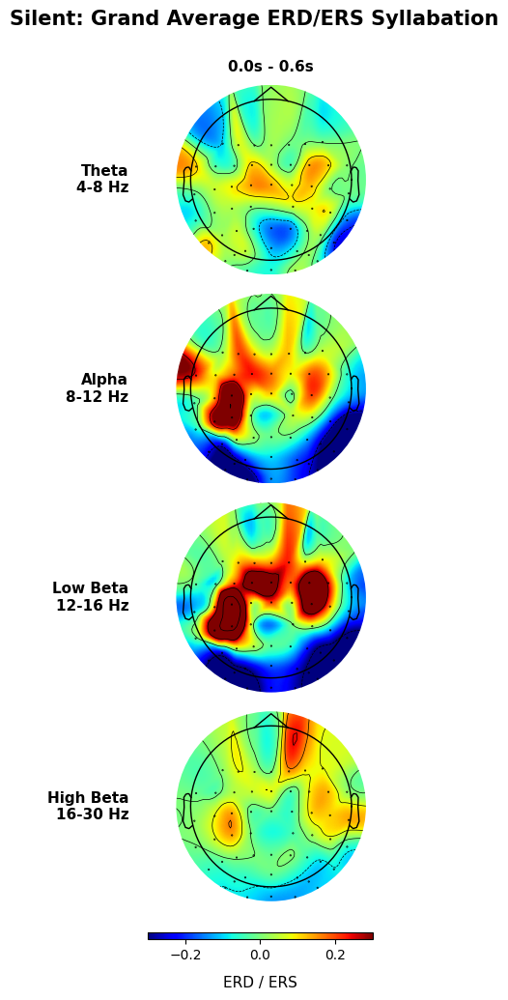

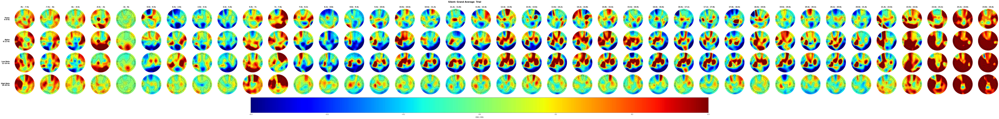

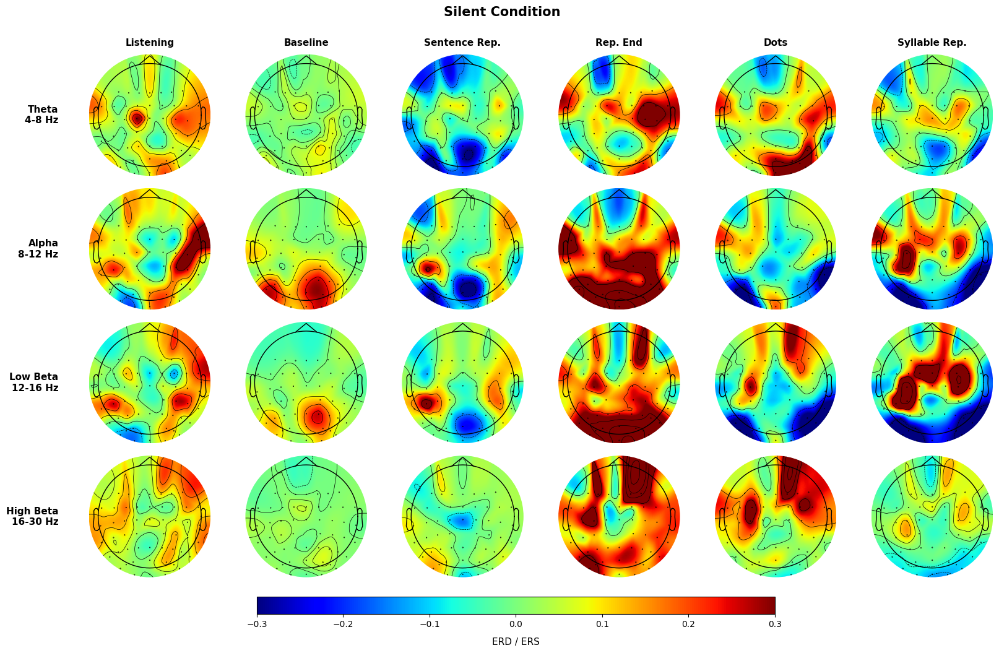

In [3]:
tfr_syll = mne.time_frequency.read_tfrs(tfr_syll_file)
tfr_full_trial = mne.time_frequency.read_tfrs(tfr_full_trial_file)
tfr_base = tfr_full_trial.copy().crop(-2,-0.1)._data.mean(axis=2, keepdims=True)

tfr_syll._data = (tfr_syll._data - tfr_base)/tfr_base

tfr_full_trial._data = (tfr_full_trial._data-tfr_base)/tfr_base
# tfr_full_trial_silent.apply_baseline(baseline=(-2,-0.1),mode='percent')
# tfr_full_trial_overt.apply_baseline(baseline=(-2,-0.1),mode='percent')

bands = {
    'Theta': (4, 8),
    'Alpha': (8, 12),
    'Low Beta': (12, 16),
    'High Beta': (16, 30) 
}

syll_times = [(0.0, 0.6)]
trial_times = [
    (-9,-7.5),# Fixation/inizio cue
    (-7.5,-6), # Cue
    (-6,-4.5),
    (-4.5,-3),
    (-3, -0), # Baseline
    (0.0, 0.5),   # Scompare la frase
    (0.5, 2.0),   # Rehearsal 1
    (2.0, 3.5),   # Rehearsal 2
    (3.5, 5.0),   # Rehearsal 3
    (5.0, 7),     # Fine Rehearsal 
    (7, 7.6),     # 3 puntini
    (7.6,8.2),    # 2 puntini
    (8.2, 8.8),   # 1 puntini
    *[(np.round((8.8+i*0.6),2),np.round((9.4+i*0.6),2)) for i in range(26)] # syllables
]

vlim = [-0.6,0.6] if mode == 'overt' else [-0.3,0.3]
vlim_silent = None


# Plot Silent
fig = plot_erd_grid(tfr_syll, bands, syll_times,  vlim=vlim,cmap='jet',
              title=f'{mode.capitalize()}: Grand Average ERD/ERS Syllabation')
fig.set_size_inches(5,13)
plt.savefig(figures_path / f"{mode}_csd_erd_syllabation({syll_times[0][0]},{syll_times[-1][1]}s).png",dpi=300)
plt.show()


plot_erd_grid(tfr_full_trial, bands, trial_times, vlim=vlim,cmap='jet',
              title=f'{mode.capitalize()}: Grand Average  Trial')
plt.savefig(figures_path / f"{mode}_csd_erd_full.png",dpi=300)
plt.show()


times = {   'Listening': (-6.5,-3.5),
            'Baseline': (-3,0),
            'Sentence Rep.': (1,4),
            'Rep. End': (6,7),
            'Dots': (7,8.8),
            'Syllable Rep.': ((8.8,8.8+0.6*20))}

fig = plot_erd_grid(tfr_full_trial, bands, times, vlim=vlim,cmap='jet',
              title=f'{mode.capitalize()} Condition')
plt.savefig(figures_path / f"{mode}_csd_erd_trial_sint.png",dpi=300)
plt.show()

In [28]:
events, ev_map = mne.events_from_annotations(raw, event_id='auto')

ev_id = ev_map['782']
target_epoch = (-10,5+2+0.6*6+0.6*5+0.1)
t_baseline = (-2,-0.2)

baseline = None
freqs = np.arange(4, 50, 1)
n_cycles = freqs / 2.0
padded_epoch = (target_epoch[0] - 1, target_epoch[1] + 1)
reject = dict(eeg=300e-6) if mode=='silent' else dict(eeg=500e-6)

# 1. Epoch without baselining yet, using Volts for rejection
epochs = mne.Epochs(raw, events, ev_id, padded_epoch[0], padded_epoch[1], 
                    proj=True, picks='eeg', 
                    baseline=None,       # Turn off baselining here
                    reject=reject, 
                    preload=True)

# 2. Compute CSD on the clean epochs
epochs_csd = mne.preprocessing.compute_current_source_density(epochs)

# 3. Apply the baseline correction to the CSD data
epochs_csd.apply_baseline(t_baseline)

tfr = epochs.compute_tfr(method="morlet",freqs=freqs, n_cycles=n_cycles, use_fft=True,
                return_itc=False, average=True, n_jobs=8, verbose='error')
tfr.apply_baseline(baseline=t_baseline, mode='percent')

tfr.crop(target_epoch[0], target_epoch[1])

Used Annotations descriptions: [np.str_('1'), np.str_('3138'), np.str_('3139'), np.str_('3140'), np.str_('3141'), np.str_('3142'), np.str_('3143'), np.str_('3144'), np.str_('3145'), np.str_('3146'), np.str_('3147'), np.str_('3148'), np.str_('3149'), np.str_('3150'), np.str_('3151'), np.str_('3152'), np.str_('3153'), np.str_('3154'), np.str_('3155'), np.str_('3156'), np.str_('3157'), np.str_('780'), np.str_('781'), np.str_('782'), np.str_('786'), np.str_('897'), np.str_('cue_ai'), np.str_('cue_al'), np.str_('cue_alberi'), np.str_('cue_alla'), np.str_('cue_allegra'), np.str_('cue_alti'), np.str_('cue_ancora'), np.str_('cue_annaffia'), np.str_('cue_argomento'), np.str_('cue_arriva'), np.str_('cue_ascolta'), np.str_('cue_assolato'), np.str_('cue_bambini'), np.str_('cue_bambino'), np.str_('cue_basilico'), np.str_('cue_beve'), np.str_('cue_bianca'), np.str_('cue_blu'), np.str_('cue_brilla'), np.str_('cue_caldo'), np.str_('cue_cammina'), np.str_('cue_cani'), np.str_('cue_cappotto'), np.str_('

Not setting metadata
20 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 20 events and 6580 original time points ...
0 bad epochs dropped
Fitted sphere radius:         92.8 mm
Origin head coordinates:      1.0 -19.1 8.3 mm
Origin device coordinates:    1.0 -19.1 8.3 mm
Applying baseline correction (mode: mean)
Applying baseline correction (mode: percent)


Data type,Average Power Estimates
Data source,Epochs
Number of epochs,52
Dims,"channel, freq, time"
Estimation method,morlet
Number of channels,52
Number of timepoints,6068
Number of frequency bins,46
Frequency range,4.00 – 49.00 Hz


## Phase analysis

In [3]:
from scipy.signal import hilbert
def compute_hilbert(data):
    analytic_signal = hilbert(data, axis=-1)
    amplitude_envelope = np.abs(analytic_signal)
    instantaneous_phase = np.angle(analytic_signal)
    return amplitude_envelope, instantaneous_phase

def plot_PLV(plv,times):
    if len(times)<=128:
        w=5
    elif len(times)<=1000:
        w=7
    else:
        w=10
    plt.figure(figsize=(w,7))
    plt.imshow(plv, aspect='auto', origin='lower', cmap='viridis', 
               extent=[times[0], times[-1], 0, plv.shape[0]],
               interpolation=None)
    plt.colorbar(label='PLV')
    plt.yticks(np.arange(plv.shape[0])+0.5, epochs.ch_names)
    plt.xlabel('Time (s)')
    plt.ylabel('Channels')
    plt.title('Phase Locking Value (PLV) across Channels')

In [ ]:
events_df = get_events_df(raw)

events_df[events_df.type=='Word'].head(10)

events_df[events_df.type=='Word'].groupby('sequence_id').first().reset_index().head(10)

,time,duration,description,ev_code,text,type
3,4.58608,0.17,cue_il,NaN,il,Word
4,4.75608,0.50,cue_ragazzo,NaN,ragazzo,Word
5,5.25608,0.47,cue_ascolta,NaN,ascolta,Word
6,5.72608,0.11,cue_la,NaN,la,Word
7,5.83608,0.43,cue_musica,NaN,musica,Word
8,6.26608,0.46,cue_allegra,NaN,allegra,Word
9,6.72608,0.35,cue_mentre,NaN,mentre,Word
10,7.07608,0.42,cue_cammina,NaN,cammina,Word
11,7.49608,0.33,cue_verso,NaN,verso,Word
12,7.82608,0.10,cue_la,NaN,la,Word


In [ ]:
syll_trigg_ev_id = ev_map['781']
syll_onset_ev_id = [v for k,v in ev_map.items() if k.startswith('syll_')]

sentence_trigg_ev_id = ev_map['782']
sentence_onset_ev_id = [v for k,v in ev_map.items() if k.startswith('sentence_')]

[349,
 350,
 351,
 352,
 353,
 354,
 355,
 356,
 357,
 358,
 359,
 360,
 361,
 362,
 363,
 364,
 365,
 366,
 367,
 368,
 369,
 370,
 371,
 372,
 373,
 374,
 375,
 376,
 377,
 378,
 379,
 380,
 381,
 382,
 383,
 384,
 385,
 386,
 387,
 388,
 389,
 390,
 391,
 392,
 393,
 394,
 395,
 396,
 397,
 398,
 399,
 400,
 401,
 402,
 403,
 404,
 405,
 406,
 407,
 408,
 409,
 410,
 411,
 412,
 413,
 414,
 415,
 416,
 417,
 418,
 419,
 420,
 421,
 422,
 423,
 424,
 425,
 426,
 427,
 428,
 429,
 430,
 431,
 432,
 433,
 434,
 435,
 436,
 437,
 438,
 439,
 440,
 441,
 442,
 443,
 444,
 445,
 446,
 447,
 448,
 449,
 450,
 451,
 452,
 453,
 454,
 455,
 456,
 457,
 458,
 459,
 460,
 461,
 462,
 463,
 464,
 465,
 466,
 467,
 468,
 469,
 470,
 471,
 472,
 473,
 474,
 475,
 476,
 477,
 478,
 479,
 480,
 481,
 482,
 483,
 484,
 485,
 486,
 487,
 488,
 489,
 490,
 491,
 492,
 493,
 494,
 495,
 496,
 497,
 498,
 499,
 500,
 501,
 502,
 503,
 504,
 505,
 506,
 507,
 508,
 509,
 510,
 511,
 512,
 513,
 514,
 515

_________ (Subject k7) _________ 
Not setting metadata
1386 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1386 events and 4225 original time points ...
51 bad epochs dropped


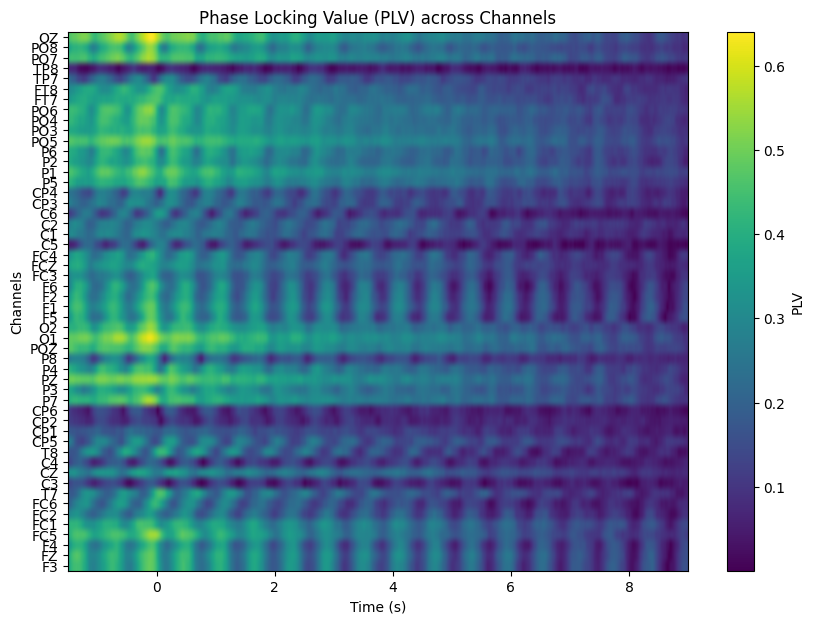

In [4]:
# ev_baseline = events_df.groupby('sequence_id').first().reset_index()
# events = np.array([(int(ev.start*raw.info['sfreq']), 0, 0) for ev in ev_baseline.itertuples()])

# ev_id = ev_map['781'] 
ev_id = [v for k,v in ev_map.items() if k.startswith('syll_')]

subj_subset = ['k7','i5','k3','i1','k4','j8','c9', 'j4','j5','j8']
subj_subset = ['k7']
# subj_subset = subjects

target_epoch = (-1.5, 9) if not ev_id in [3,12,13] else (-0.1, 0.4)
baseline = (-1.5, -0.1) if not ev_id in [3,12,13] else None
# baseline =  None
band = (0.5, 4)
# band = (8,12)

pad = (max(1/(band[0])*1.5,0.3)) # 1.5 cicli alla frequenza più bassa della banda di interesse
padded_epoch = (target_epoch[0] - pad, target_epoch[1] + pad)

all_subjects_plv = []
raw_filtered = raw.copy().filter(band[0],band[1], verbose='error')
for subj in subj_subset:
    print(f"_________ (Subject {subj}) _________ ")
    epochs = mne.Epochs(raw_filtered, events, ev_id, padded_epoch[0], padded_epoch[1], 
                        proj=True, picks='eeg', baseline=baseline, 
                        reject=dict(eeg=500e-6), preload=True, 
                        # verbose='error'
                        )
    
    amplitude_envelope, instantaneous_phase = compute_hilbert(epochs.get_data())
    
    plv = np.abs(np.mean(np.exp(1j * instantaneous_phase), axis=0))
    mask = (epochs.times >= target_epoch[0]) & (epochs.times <= target_epoch[1])

    plv_cropped = plv[:, mask]
    
    # Appendiamo il dato pulito
    all_subjects_plv.append(plv_cropped[None, :, :])

times = epochs.times[mask]

all_subjects_plv = np.vstack(all_subjects_plv)

grand_average_plv = np.mean(all_subjects_plv, axis=0)


epochs.crop(tmin=target_epoch[0], tmax=target_epoch[1])

plot_PLV(grand_average_plv, times)
plt.show()
